# I. Impact environnemental de l’alimentation
- Comparer les impacts environnementaux des grands groupes d’aliments
- Statistiques descriptives + visualisation
- Comparer en particulier les produits animaux et végétaux
- Identifier les principaux postes responsables de l’impact climatique : agriculture, transformation, emballage, transport...

# II. Les alternatives végétales : vraiment meilleures ?
- Identifier les principales catégories d’alternatives végétales
- Comparer leurs impacts environnementaux avec ceux des produits animaux qu’elles peuvent remplacer
- Comparer leur profil nutritionnel et étudier colonne SAIN et LIM
- Voir si certaines alternatives végétales présentent effectivement un compromis entre impact environnemental et qualité nutritionnelle
# III. Santé et environnement : existe-t-il un double gain ?
- Chercher les aliments qui combinent faible impact environnemental et bonne qualité nutritionnelle
- Comparer notamment les profils des aliments animaux, végétaux et alternatives végétales
- Conclure sur l’existence ou non d’un arbitrage santé–environnement, et sur les aliments qui semblent permettre un double gain

# Présentation de la base de données fusionnée
Nous utilisons comme base de données finale pour l’analyse la base fusionnée database.csv.
Cette base regroupe des informations sur les produits alimentaires, leur composition nutritionnelle et leurs impacts environnementaux. 
Elle contient 34 variables, qu'on peut regrouper en catégories :
- Identification et classification des produits : code_agb (code d’identification d’Agribalyse), code_ciqual (code d’identification de Ciqual), groupe_aliment, sous_groupe_aliment, nom_produit, nom_lci (nom du produit en anglais), preparation (informations relatives à la préparation ou à la conservation du produit) et dqr (note de qualité des données).
- Impacts environnementaux : score_unique_ef, changement_climatique, utilisation_du_sol, epuisement_ressources_eau, particules_fines, toxicite_humaine_non_cancerogenes et toxicite_humaine_cancerogenes. Ces indicateurs sont exprimés pour 1 kg de produit alimentaire. Par exemple, le score_unique_ef est un indicateur synthétique regroupant plusieurs impacts environnementaux. Le changement_climatique, exprimé en kg CO₂ eq, mesure la contribution du produit au changement climatique. Enfin, par exemple, l’epuisement_ressources_eau, exprimé en m³ Eau eq, prend en compte la consommation d’eau. 
- Répartition de l’impact climatique selon les étapes du cycle de vie : changement_climatique_agriculture, changement_climatique_transformation, changement_climatique_emballage, changement_climatique_transport, changement_climatique_distribution et changement_climatique_consommation. Ces variables permettent d’identifier la contribution des différentes étapes du cycle de vie à l’impact climatique d'un produit.
- Composition nutritionnelle : la base renseigne l’énergie, les protéines, les glucides, les lipides, les sucres, les fibres alimentaires, le sel, le calcium, le fer, le sodium et la vitamine C.
- Scores alimentaires : SAIN et LIM. Ils sont définis dans Exploration_nettoyage_Ciqual.ipynb.

In [9]:
# Chargement de la base de données fusionnée
import pandas as pd
import matplotlib.pyplot as plt

database = pd.read_csv("data/database.csv")

print("Dimensions de la base :", database.shape)
database.head(5)

Dimensions de la base : (2296, 34)


,code_agb,code_ciqual,groupe_aliment,sous_groupe_aliment,nom_produit,nom_lci,preparation,dqr,score_unique_ef,changement_climatique,...,Lipides (g 100 g),Sucres (g 100 g),Fibres alimentaires (g 100 g),Sel chlorure de sodium (g 100 g),Calcium (mg 100 g),Fer (mg 100 g),Sodium (mg 100 g),Vitamine C (mg 100 g),SAIN,LIM
0,11172,11172,aides culinaires et ingrédients divers,aides culinaires,"Court-bouillon pour poissons, déshydraté","Aromatic stock cube, for fish, dehydrated",Pas de préparation,2.24,1.870,7.58,...,23.00,4.50,2.50,47.500,0.0,0.00,19000.0,0.0,1.370826,100.000000
1,25525,25525,aides culinaires et ingrédients divers,aides culinaires,"Pizza, sauce garniture pour",Topping sauce for pizza,Pas de préparation,2.19,0.148,0.94,...,0.75,4.57,2.81,0.960,50.0,0.90,385.0,7.0,16.109676,7.258677
2,11214,11214,aides culinaires et ingrédients divers,aides culinaires,"Préparation culinaire à base de soja, type ""cr...","Soy ""cream"" preparation",Pas de préparation,1.75,0.148,1.17,...,14.70,1.60,0.00,0.063,16.0,0.47,25.0,0.0,1.404142,3.830630
3,11084,11084,aides culinaires et ingrédients divers,algues,"Agar (algue), cru","Seaweed, agar, raw",Pas de préparation,2.77,1.550,11.80,...,0.03,0.28,0.50,0.023,54.0,1.86,9.0,0.0,16.397663,0.290785
4,20995,20995,aides culinaires et ingrédients divers,algues,"Ao-nori (Enteromorpha sp.), séchée ou déshydratée","Sea lettuce (Enteromorpha sp.), dried or dehyd...",Pas de préparation,2.77,1.550,11.80,...,2.50,1.35,35.10,10.200,1550.0,205.00,4090.0,48.8,100.000000,44.917791


La base de données fusionnée contient 2296 lignes et 34 colonnes. 

# I. Impact environnemental de l'alimentation

Dans cette première partie, nous analysons les impacts environnementaux des différents groupes alimentaires. 

## I.1. Comparaison des impacts environnementaux des grands groupes alimentaires

In [4]:
# Nombre de groupes et de sous-groupes alimentaires
print("Nombre de groupes alimentaires :", database["groupe_aliment"].nunique())
print("Nombre de sous-groupes alimentaires :", database["sous_groupe_aliment"].nunique())

# Nombre de sous-groupes et de produits par groupe alimentaire
composition_groupes = database.groupby("groupe_aliment").agg(
    nombre_sous_groupes=("sous_groupe_aliment", "nunique"),
    nombre_produits=("nom_produit", "count")
)

# Affichage du tableau
display(composition_groupes.sort_values("nombre_produits", ascending=False))

Nombre de groupes alimentaires : 11
Nombre de sous-groupes alimentaires : 60


,nombre_sous_groupes,nombre_produits
groupe_aliment,,
"viandes, œufs, poissons",12,637
"fruits, légumes, légumineuses et oléagineux",5,391
produits céréaliers,5,333
entrées et plats composés,7,300
lait et produits laitiers,4,196
aides culinaires et ingrédients divers,9,156
boissons,3,134
produits sucrés,4,48
aliments infantiles,4,38


La base de données distingue 11 groupes alimentaires : viandes, œufs, poissons ; fruits, légumes, légumineuses et oléagineux ; produits céréaliers ; entrées et plats composés ; lait et produits laitiers ; aides culinaires et ingrédients divers ; boissons ; produits sucrés ; aliments infantiles ; matières grasses ; glaces et sorbets. Le groupe « viandes, œufs, poissons » est le plus représenté, avec 12 sous-groupes et 637 produits.

In [5]:
# Comparaison des impacts environnementaux des grands groupes d’aliments

# Liste des indicateurs environnementaux disponibles dans la base fusionnée
indicateurs = [
    "score_unique_ef",
    "changement_climatique",
    "utilisation_du_sol",
    "epuisement_ressources_eau",
    "particules_fines",
    "toxicite_humaine_non_cancerogenes",
    "toxicite_humaine_cancerogenes"
]

# Calcul des statistiques environnementales par groupe alimentaire
stats_groupes = database.groupby("groupe_aliment").agg(
    nombre_produits=("nom_produit", "count"),
    **{
        indicateur + "_moyenne": (indicateur, "mean")
        for indicateur in indicateurs
    },
    **{
        indicateur + "_mediane": (indicateur, "median")
        for indicateur in indicateurs
    }
)

# Affichage des résultats
display(stats_groupes)

,nombre_produits,score_unique_ef_moyenne,changement_climatique_moyenne,utilisation_du_sol_moyenne,epuisement_ressources_eau_moyenne,particules_fines_moyenne,toxicite_humaine_non_cancerogenes_moyenne,toxicite_humaine_cancerogenes_moyenne,score_unique_ef_mediane,changement_climatique_mediane,utilisation_du_sol_mediane,epuisement_ressources_eau_mediane,particules_fines_mediane,toxicite_humaine_non_cancerogenes_mediane,toxicite_humaine_cancerogenes_mediane
groupe_aliment,,,,,,,,,,,,,,,
aides culinaires et ingrédients divers,156,0.491599,3.806494,170.781154,4.013111,3.115596e-07,6.355372e-08,2.152250e-09,0.2990,2.3650,83.85,2.4750,1.760000e-07,4.465000e-08,1.215000e-09
aliments infantiles,38,0.200318,1.749921,74.329211,1.052105,1.437737e-07,2.420789e-08,1.844553e-09,0.1440,1.2100,50.50,0.9420,7.325000e-08,1.895000e-08,6.510000e-10
boissons,134,0.143213,1.237856,45.530680,1.350146,7.808706e-08,3.619228e-08,1.080540e-09,0.1170,0.8345,19.05,0.3670,5.550000e-08,1.185000e-08,4.705000e-10
entrées et plats composés,300,0.595310,4.770027,236.383667,3.492481,4.998105e-07,7.362200e-08,2.925997e-09,0.4230,3.2700,136.00,1.1700,2.790000e-07,4.815000e-08,2.225000e-09
"fruits, légumes, légumineuses et oléagineux",391,0.219991,1.478141,135.115217,3.671992,1.063481e-07,4.673046e-08,1.869307e-09,0.1360,1.0400,33.20,0.6820,6.050000e-08,2.300000e-08,8.380000e-10
glaces et sorbets,25,0.259720,2.094400,74.880000,1.196920,1.545760e-07,2.548400e-08,1.061880e-09,0.2380,1.9800,67.70,0.6660,1.600000e-07,2.500000e-08,1.060000e-09
lait et produits laitiers,196,0.476781,4.472602,230.414796,1.024429,4.404061e-07,5.433265e-08,2.231036e-09,0.5005,5.1900,239.00,0.6920,4.270000e-07,6.090000e-08,2.450000e-09
matières grasses,38,0.572816,4.957105,345.928947,7.515579,3.867368e-07,9.436316e-08,4.504658e-09,0.4435,3.6250,339.50,0.8625,2.905000e-07,6.370000e-08,3.320000e-09
produits céréaliers,333,0.298500,2.617913,143.727027,2.533186,1.776829e-07,7.203012e-08,1.656595e-09,0.2840,2.2400,134.00,1.0100,1.700000e-07,3.000000e-08,1.550000e-09


In [6]:
# Recherche des groupes ayant les impacts les plus élevés

for indicateur in indicateurs:
    print(indicateur)
    print("Moyenne maximale :", stats_groupes[indicateur + "_moyenne"].idxmax())
    print("Médiane maximale :", stats_groupes[indicateur + "_mediane"].idxmax())

score_unique_ef
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : viandes, œufs, poissons
changement_climatique
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : viandes, œufs, poissons
utilisation_du_sol
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : matières grasses
epuisement_ressources_eau
Moyenne maximale : matières grasses
Médiane maximale : aides culinaires et ingrédients divers
particules_fines
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : viandes, œufs, poissons
toxicite_humaine_non_cancerogenes
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : viandes, œufs, poissons
toxicite_humaine_cancerogenes
Moyenne maximale : viandes, œufs, poissons
Médiane maximale : viandes, œufs, poissons


Le groupe viandes, œufs et poissons présente la moyenne et la médiane les plus élevées pour 5 indicateurs sur 7. Il possède notamment le score unique EF moyen le plus élevé (1,64) et l’impact climatique moyen le plus élevé (13,18 kg CO₂ eq/kg), ainsi que les médianes les plus élevées pour ces deux indicateurs (1,27 et 7,75 kg CO₂ eq/kg). Les résultats diffèrent pour l'utilisation des sols : les viandes, œufs et poissons ont la moyenne la plus élevée, mais les matières grasses ont la médiane la plus élevée. L'épuisement des ressources en eau présente un résultat différent : les matières grasses ont la moyenne la plus élevée, tandis que les aides culinaires et ingrédients divers ont la médiane la plus élevée.

In [7]:
# Recherche des groupes ayant les impacts les plus faibles

for indicateur in indicateurs:
    print(indicateur)
    print("Moyenne minimale :", stats_groupes[indicateur + "_moyenne"].idxmin())
    print("Médiane minimale :", stats_groupes[indicateur + "_mediane"].idxmin())

score_unique_ef
Moyenne minimale : boissons
Médiane minimale : boissons
changement_climatique
Moyenne minimale : boissons
Médiane minimale : boissons
utilisation_du_sol
Moyenne minimale : boissons
Médiane minimale : boissons
epuisement_ressources_eau
Moyenne minimale : lait et produits laitiers
Médiane minimale : boissons
particules_fines
Moyenne minimale : boissons
Médiane minimale : boissons
toxicite_humaine_non_cancerogenes
Moyenne minimale : aliments infantiles
Médiane minimale : boissons
toxicite_humaine_cancerogenes
Moyenne minimale : glaces et sorbets
Médiane minimale : boissons


Les boissons ont globalement les impacts environnementaux les plus faibles parmi les 11 groupes alimentaires, avec notamment un score unique EF médian de 0,117 et un impact climatique médian de 0,83 kg CO₂ eq/kg.

Le graphique ci-dessous présente la médiane de l’indicateur « changement climatique » pour chaque groupe alimentaire.

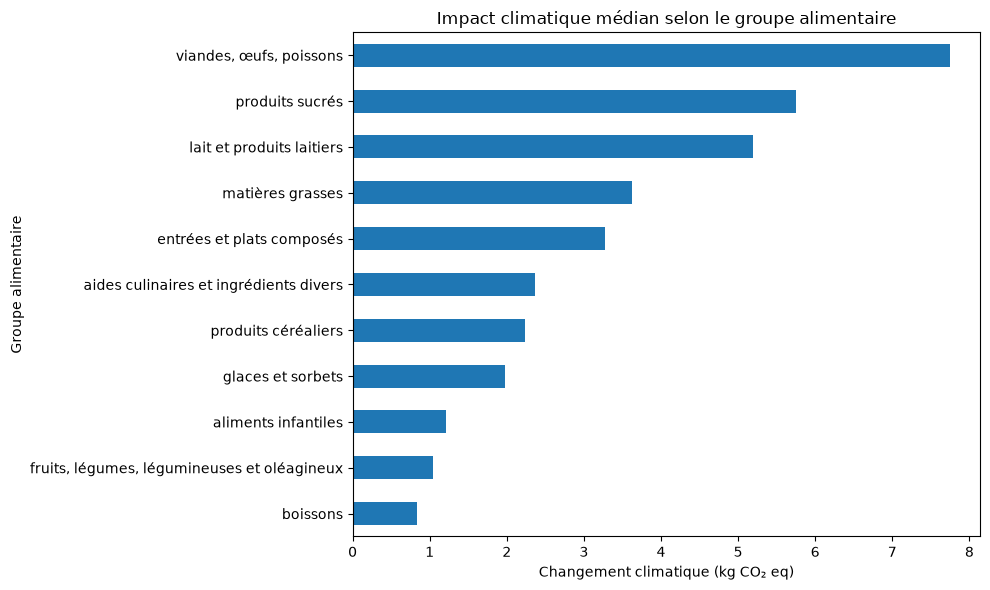

In [10]:
# Graphique sur l'impact climatique médian des groupes alimentaires

impact_climatique_groupes = (
    database.groupby("groupe_aliment")["changement_climatique"]
    .median()
    .sort_values()
)

plt.figure(figsize=(10, 6))

impact_climatique_groupes.plot(kind="barh")

plt.xlabel("Changement climatique (kg CO₂ eq)")
plt.ylabel("Groupe alimentaire")
plt.title("Impact climatique médian selon le groupe alimentaire")

plt.tight_layout()
plt.show()

Ce graphique montre que le groupe « viandes, œufs, poissons » présente l'impact climatique médian le plus élevé parmi les groupes alimentaires étudiés. 

Après avoir identifié les groupes alimentaires présentant les impacts environnementaux les plus élevés, notamment en matière de changement climatique, il convient maintenant de déterminer quelles étapes du cycle de vie des produits contribuent le plus à leur impact climatique (agriculture, transformation, emballage, transport, distribution et consommation).

## I.2. Identification des principaux postes responsables de l’impact climatique

In [11]:
# Identification des principaux postes du cycle de vie responsables de l’impact climatique

postes_climatiques = [
    "changement_climatique_agriculture",
    "changement_climatique_transformation",
    "changement_climatique_emballage",
    "changement_climatique_transport",
    "changement_climatique_distribution",
    "changement_climatique_consommation"
]

# Calcul de la moyenne et de la médiane pour chaque poste
stats_postes = database[postes_climatiques].agg(["mean", "median"]).T

# Renommage des colonnes
stats_postes.columns = ["moyenne", "mediane"]

# Classement des postes selon leur impact moyen 
stats_postes = stats_postes.sort_values(
    "moyenne", ascending=False
)

# Affichage du tableau final
display(stats_postes)

,moyenne,mediane
changement_climatique_agriculture,4.731860,1.65000
changement_climatique_emballage,0.456006,0.40100
changement_climatique_transport,0.388006,0.28350
changement_climatique_transformation,0.250495,0.17050
changement_climatique_consommation,0.045827,0.00683
changement_climatique_distribution,0.036326,0.03680


Les résultats montrent que l'agriculture constitue le principal contributeur à l'impact climatique des produits alimentaires étudiés, avec un impact moyen d'environ 4,73 kg CO₂ eq par kg de produit. 

In [12]:
# Identification des principaux postes du cycle de vie responsables de l’impact climatique par groupe alimentaire

# Calcul de la moyenne pour chaque poste et chaque groupe
moyennes_postes_groupes = database.groupby("groupe_aliment")[postes_climatiques].mean()

# Affichage des résultats
display(moyennes_postes_groupes)

,changement_climatique_agriculture,changement_climatique_transformation,changement_climatique_emballage,changement_climatique_transport,changement_climatique_distribution,changement_climatique_consommation
groupe_aliment,,,,,,
aides culinaires et ingrédients divers,2.012561,0.343787,1.103194,0.300615,0.031270,0.011589
aliments infantiles,0.987147,0.095940,0.454197,0.182008,0.024597,0.006042
boissons,0.461191,0.136341,0.366494,0.243546,0.024331,0.005533
entrées et plats composés,3.562642,0.310883,0.473632,0.342409,0.035313,0.043431
"fruits, légumes, légumineuses et oléagineux",0.648670,0.105881,0.235987,0.363803,0.040182,0.083496
glaces et sorbets,1.071720,0.186240,0.494000,0.251440,0.066508,0.025800
lait et produits laitiers,3.519811,0.226175,0.393815,0.261138,0.035465,0.006133
matières grasses,3.690895,0.191863,0.664895,0.379184,0.027216,0.002876
produits céréaliers,1.771982,0.188643,0.412771,0.209450,0.023600,0.010852


L'agriculture est le principal poste contributeur dans les 11 groupes alimentaires. 

Après avoir identifié le groupe « viandes, œufs et poissons » comme présentant les impacts environnementaux les plus élevés, intéressons-nous aux différences entre ses sous-groupes.

## I.3. Hétérogénéité des impacts au sein du groupe « viandes, œufs et poissons »

In [13]:
# Sélection du groupe viandes, œufs et poissons
animaux = database[
    database["groupe_aliment"] == "viandes, œufs, poissons"
]

# Calcul des statistiques descriptives par sous-groupe
stats_sous_groupes = animaux.groupby("sous_groupe_aliment").agg(
    nombre_produits=("nom_produit", "count"),
    **{
        indicateur + "_moyenne": (indicateur, "mean")
        for indicateur in indicateurs
    },
    **{
        indicateur + "_mediane": (indicateur, "median")
        for indicateur in indicateurs
    }
)

# Affichage du tableau
display(stats_sous_groupes)

,nombre_produits,score_unique_ef_moyenne,changement_climatique_moyenne,utilisation_du_sol_moyenne,epuisement_ressources_eau_moyenne,particules_fines_moyenne,toxicite_humaine_non_cancerogenes_moyenne,toxicite_humaine_cancerogenes_moyenne,score_unique_ef_mediane,changement_climatique_mediane,utilisation_du_sol_mediane,epuisement_ressources_eau_mediane,particules_fines_mediane,toxicite_humaine_non_cancerogenes_mediane,toxicite_humaine_cancerogenes_mediane
sous_groupe_aliment,,,,,,,,,,,,,,,
autres produits à base de viande,13,1.780769,15.031538,1080.000000,3.275385,1.849077e-06,2.334769e-07,8.886923e-09,1.2300,7.41,445.0,3.220,1.370000e-06,1.160000e-07,7.850000e-09
charcuteries,142,1.114141,9.033169,492.412676,2.508718,9.952465e-07,1.116401e-07,6.121479e-09,0.9695,7.42,374.0,2.405,7.965000e-07,8.390000e-08,5.390000e-09
mollusques et crustacés crus,13,1.582769,11.678462,146.263846,28.120615,1.075769e-06,1.309077e-07,8.500000e-09,1.3300,9.89,243.0,0.965,1.290000e-06,7.000000e-08,5.720000e-09
mollusques et crustacés cuits,7,2.830571,18.808571,120.990000,32.099286,2.073000e-06,2.628429e-07,1.747714e-08,1.6200,11.80,89.0,0.847,1.610000e-06,8.640000e-08,6.980000e-09
poissons crus,94,1.427574,8.315426,39.289149,8.733564,1.364191e-06,7.843511e-08,4.679596e-09,1.5700,8.42,16.2,0.470,1.320000e-06,5.650000e-08,4.670000e-09
poissons cuits,55,1.684345,9.753818,76.576364,20.247127,1.524000e-06,8.864909e-08,5.830000e-09,1.5800,9.22,24.2,0.709,1.100000e-06,7.060000e-08,6.080000e-09
produits à base de poissons et produits de la mer,45,0.988022,6.572889,106.074667,3.830689,1.011089e-06,6.824667e-08,6.130000e-09,0.8610,6.11,60.7,0.635,6.830000e-07,5.710000e-08,4.880000e-09
substituts de charcuterie,3,0.274333,2.120000,126.766667,0.556333,1.140667e-07,4.046667e-08,2.370000e-09,0.3020,2.17,134.0,0.577,1.230000e-07,3.590000e-08,2.270000e-09
substituts de viande,8,0.252688,2.013750,110.162500,2.920375,1.149000e-07,3.817125e-08,1.422750e-09,0.2440,2.02,115.0,0.590,1.060000e-07,2.745000e-08,1.410000e-09


In [ ]:
# Recherche des sous-groupes ayant les impacts les plus élevés
for indicateur in indicateurs:
    print("\n", indicateur)
    print("Moyenne maximale :", stats_sous_groupes[indicateur + "_moyenne"].idxmax())
    print("Médiane maximale :", stats_sous_groupes[indicateur + "_mediane"].idxmax())

On constate que les viandes cuites présentent les médianes les plus élevées pour les sept indicateurs environnementaux étudiés.

In [ ]:
# Recherche des sous-groupes ayant les impacts les plus faibles
for indicateur in indicateurs:
    print("\n", indicateur)
    print("Moyenne minimale :", stats_sous_groupes[indicateur + "_moyenne"].idxmin())
    print("Médiane minimale :", stats_sous_groupes[indicateur + "_mediane"].idxmin())

Les substituts de viande présentent globalement les impacts les plus faibles parmi les sous-groupes étudiés.

Si l'on se concentre sur l’impact climatique et le score unique EF global, on constate que les impacts environnementaux sont très hétérogènes au sein du groupe viandes, œufs et poissons. 
Les viandes cuites et crues présentent les impacts climatiques médians les plus élevés, tandis que les œufs et surtout les substituts de viande et de charcuterie présentent des impacts nettement plus faibles. 
Par exemple, la médiane de l'impact climatique des viandes cuites est de 29,70 kg CO₂ eq/kg de produit, contre 2,02 kg CO₂ eq/kg pour les substituts de viande. De plus, les viandes cuites présentent un score unique EF médian de 2,82, contre 0,244 pour les substituts de viande. Ce score est un indicateur synthétique qui regroupe plusieurs impacts environnementaux en un seul indicateur. 
Cependant, ces sous-groupes sont représentés par des effectifs très différents dans la base : les viandes cuites comptent 104 produits et les viandes crues 132, contre 3 produits pour les substituts de charcuterie et 8 pour les substituts de viande. 

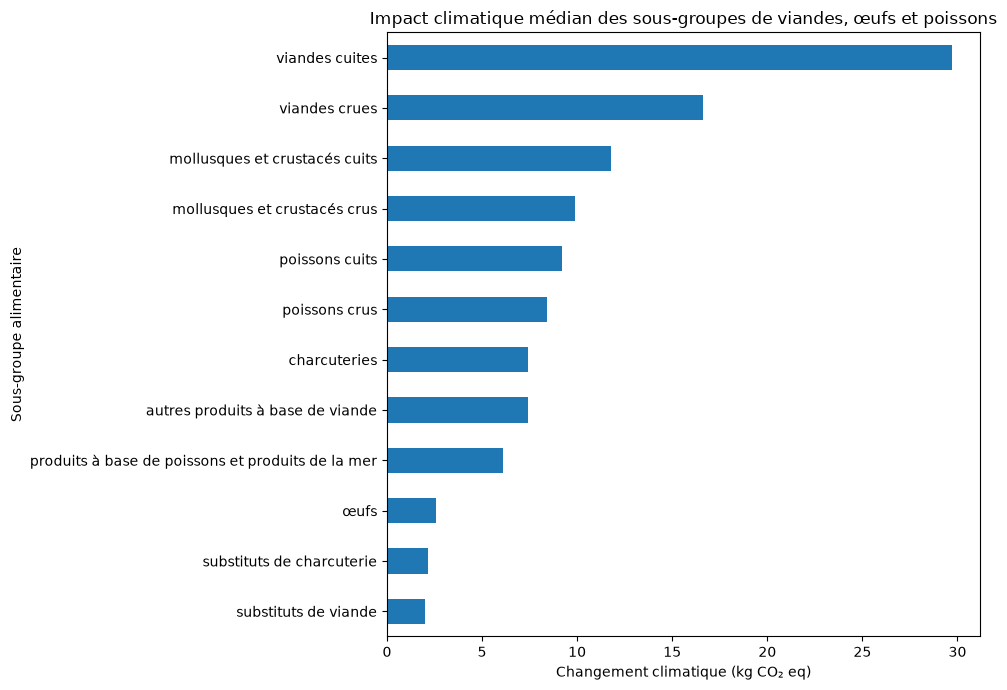

In [14]:
# Graphique sur l'impact climatique médian des sous-groupes
# du groupe "viandes, œufs et poissons"

impact_climatique_sous_groupes = (
    database[
        database["groupe_aliment"] == "viandes, œufs, poissons"
    ]
    .groupby("sous_groupe_aliment")["changement_climatique"]
    .median()
    .sort_values()
)

plt.figure(figsize=(10, 7))

impact_climatique_sous_groupes.plot(kind="barh")

plt.xlabel("Changement climatique (kg CO₂ eq)")
plt.ylabel("Sous-groupe alimentaire")
plt.title(
    "Impact climatique médian des sous-groupes "
    "de viandes, œufs et poissons"
)

plt.tight_layout()
plt.show()

Ce graphique permet de visualiser les impacts climatiques médians des différents sous-groupes. Il met en évidence l'impact élevé des viandes cuites.

# II. Les alternatives végétales : une alternative aux produits carnés ?

L'alimentation végétarienne repose sur l'exclusion de la viande et du poisson. Elle nécessite donc de trouver d'autres sources de protéines et de nutriments habituellement apportés par les produits carnés. Dans cette partie, nous cherchons à étudier les principales alternatives végétales susceptibles de contribuer à ces apports nutritionnels, et à les comparer aux produits carnés.

Nous distinguons ainsi deux grandes familles :
- Les produits carnés, comprenant les viandes, les charcuteries et les poissons.
- Les alternatives végétales, comprenant les légumineuses, les fruits à coque et graines oléagineuses, ainsi que les substituts végétaux de viande et de charcuterie et plats végétariens.


Les alternatives végétales ont été choisi en suivant les conseils de spécialistes de l'alimentation, qui présentent ces produits comme des alternatives aux produits carnés pour subvenir correctement à nos besoins. En effet :
    - Les légumineuses (lentilles, pois chiches, haricots…) sont une source importante de protéines végétales et de fibres.
    - Les fruits à coque et graines oléagineuses (noix, amandes, noisettes, graines…) apportent des lipides, des protéines, des fibres et différents micronutriments. Ils constituent des aliments intéressants pour compléter l'alimentation végétarienne, même s'ils ne remplacent pas directement la viande.
    - Les substituts végétaux (tofu, produits à base de soja, substituts de charcuterie…) sont conçus pour reproduire certaines caractéristiques des produits carnés, notamment leur apport en protéines.
    - Les plats végétariens permettent d'étudier des préparations sans viande ni poisson, mais leur intérêt nutritionnel dépend fortement de leur composition.

## 2.1. Constitution et analyse de la base d'étude

In [18]:
# 1. Création d'une copie temporaire de la base
analyse_vegetale = database.copy()


# 2. Définition des catégories alimentaires

produits_carnes = [
    "viandes crues",
    "viandes cuites",
    "charcuteries",
    "autres produits à base de viande",
    "poissons crus",
    "poissons cuits",
    "produits à base de poissons et produits de la mer",
    "mollusques et crustacés crus",
    "mollusques et crustacés cuits"
]

alternatives_vegetales = [
    "légumineuses",
    "fruits à coque et graines oléagineuses",
    "substituts de viande",
    "substituts de charcuterie",
    "plats végétariens"
]


# 3. Classement des produits
analyse_vegetale["categorie_analyse"] = None

analyse_vegetale.loc[
    analyse_vegetale["sous_groupe_aliment"].isin(produits_carnes),
    "categorie_analyse"
] = "Produits carnés"

analyse_vegetale.loc[
    analyse_vegetale["sous_groupe_aliment"].isin(alternatives_vegetales),
    "categorie_analyse"
] = "Alternatives végétales"


# 4. Conservation des produits appartenant aux deux catégories
analyse_vegetale = analyse_vegetale.dropna(
    subset=["categorie_analyse"]
).copy()


# 5. Vérification des effectifs
effectifs = (
    analyse_vegetale["categorie_analyse"]
    .value_counts()
    .rename("Nombre de produits")
)

display(effectifs.to_frame())

,Nombre de produits
categorie_analyse,
Produits carnés,605
Alternatives végétales,113


## Analyse
Intro

score_unique_ef        changement_climatique         \
                                  mean median                  mean median   
categorie_analyse                                                            
Alternatives végétales           0.346  0.282                 2.260   2.13   
Produits carnés                  1.702  1.300                13.728   7.96   

                       toxicite_humaine_non_cancerogenes         \
                                                    mean median   
categorie_analyse                                                 
Alternatives végétales                               0.0    0.0   
Produits carnés                                      0.0    0.0   

                       toxicite_humaine_cancerogenes         
                                                mean median  
categorie_analyse                                            
Alternatives végétales                           0.0    0.0  
Produits carnés                                  0.0    0.0

Protéines, N x facteur de Jones (g 100 g)         \
                                                            mean median   
categorie_analyse                                                         
Alternatives végétales                                     14.20   14.1   
Produits carnés                                            19.85   19.6   

                       Glucides (g 100 g)        Lipides (g 100 g)         \
                                     mean median              mean median   
categorie_analyse                                                           
Alternatives végétales              17.78   12.3             20.25  10.20   
Produits carnés                      1.57    0.2             11.16   7.85   

                       Fibres alimentaires (g 100 g)        Fer (mg 100 g)  \
                                                mean median           mean   
categorie_analyse                                                            
Alternatives végétales                          8.28    6.7           3.08   
Produits carnés                                 0.16    0.0           1.73   

                              Calcium (mg 100 g)         SAIN           LIM  \
                       median               mean median  mean median   mean   
categorie_analyse                                                             
Alternatives végétales    2.2              94.36   69.0  7.31   6.97  10.26   
Produits carnés           0.9              20.77   11.0  6.54   5.79   8.59   

                               
                       median  
categorie_analyse              
Alternatives végétales   7.97  
Produits carnés          4.73

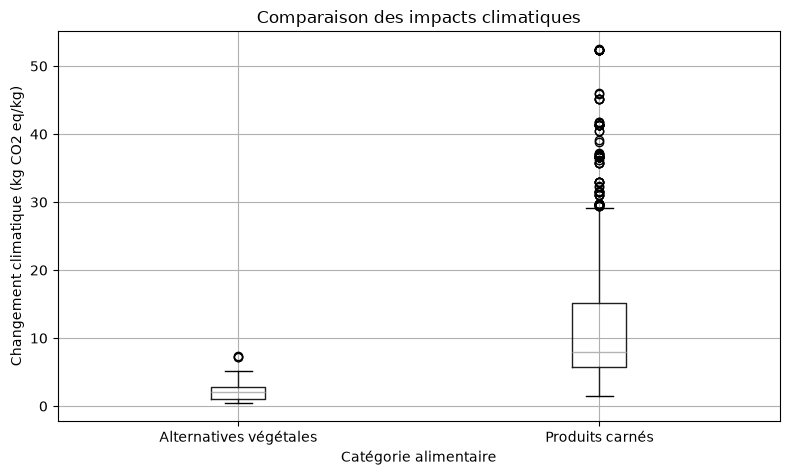

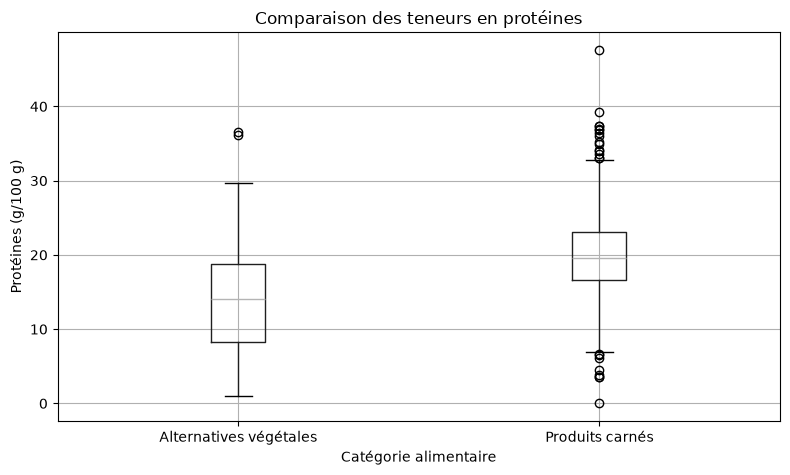

In [19]:

# 6. Comparaison des impacts environnementaux

indicateurs_env = [
    "score_unique_ef",
    "changement_climatique",
    "toxicite_humaine_non_cancerogenes",
    "toxicite_humaine_cancerogenes"
]

comparaison_env = analyse_vegetale.groupby("categorie_analyse")[
    indicateurs_env
].agg(["mean", "median"])

display(comparaison_env.round(3))


# 7. Comparaison des caractéristiques nutritionnelles

indicateurs_nutrition = [
    "Protéines, N x facteur de Jones (g 100 g)",
    "Glucides (g 100 g)",
    "Lipides (g 100 g)",
    "Fibres alimentaires (g 100 g)",
    "Fer (mg 100 g)",
    "Calcium (mg 100 g)",
    "SAIN",
    "LIM"
]

comparaison_nutrition = analyse_vegetale.groupby("categorie_analyse")[
    indicateurs_nutrition
].agg(["mean", "median"])

display(comparaison_nutrition.round(2))


# 8. Comparaison des impacts climatiques

import matplotlib.pyplot as plt

analyse_vegetale.boxplot(
    column="changement_climatique",
    by="categorie_analyse",
    figsize=(8, 5)
)

plt.title("Comparaison des impacts climatiques")
plt.suptitle("")
plt.xlabel("Catégorie alimentaire")
plt.ylabel("Changement climatique (kg CO2 eq/kg)")
plt.tight_layout()
plt.show()


# 9. Comparaison des teneurs en protéines

analyse_vegetale.boxplot(
    column="Protéines, N x facteur de Jones (g 100 g)",
    by="categorie_analyse",
    figsize=(8, 5)
)

plt.title("Comparaison des teneurs en protéines")
plt.suptitle("")
plt.xlabel("Catégorie alimentaire")
plt.ylabel("Protéines (g/100 g)")
plt.tight_layout()
plt.show()